# Tuần 7 — Giải thích URL bằng SHAP và AI Service

Tree SHAP dùng thuật toán exact trong XGBoost (`pred_contribs=True`). Đây là đóng góp log-odds; dấu dương tăng điểm phishing, dấu âm giảm điểm. Tổng base + mọi đóng góp bằng output margin, sigmoid(margin) bằng xác suất mô hình. Khi LR được chọn thì engine dùng SHAP LinearExplainer.

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "phishguard").is_dir():
    PROJECT_DIR = PROJECT_DIR.parent
if not (PROJECT_DIR / "phishguard").is_dir():
    raise FileNotFoundError("Mở notebook trong thư mục notebooks của gói dự án.")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
import matplotlib.pyplot as plt
from phishguard.engine import Engine
from phishguard.features import feature_frame


SHAP additivity residual: 6.854534149169922e-07


,feature,value,contribution,direction
0,NoOfSubDomain,0.000000,4.178579,increase
1,path_length,6.000000,3.865588,increase
2,NoOfQMarkInURL,1.000000,1.841858,increase
3,DomainLength,11.000000,1.119453,increase
4,host_entropy,3.095795,-0.686610,decrease
5,IsHTTPS,1.000000,-0.547736,decrease
6,url_entropy,4.454822,0.525557,increase
7,credential_words,2.000000,0.479607,increase


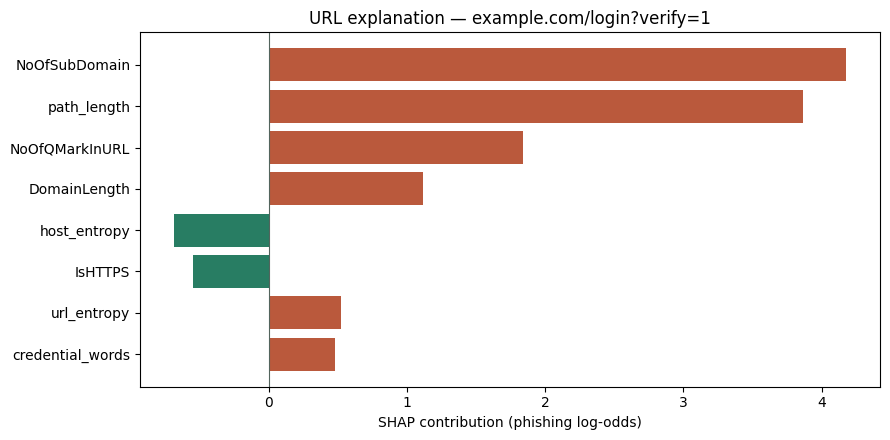

In [2]:
engine = Engine(PROJECT_DIR / "models")
result = engine.analyze("", ["https://example.com/login?verify=1"])
explanation = result["urls"][0]["shap"]
display(pd.DataFrame(explanation["top_features"]))
margin = explanation["base_value"] + sum(explanation["all_contributions"].values())
assert abs(margin - explanation["model_margin"]) < 1e-4
assert abs(1 / (1 + np.exp(-margin)) - result["urls"][0]["p_phishing"]) < 1e-5
print("SHAP additivity residual:", explanation["additivity_residual"])
fig, ax = plt.subplots(figsize=(9, 4.5))
rows = list(reversed(explanation["top_features"]))
ax.barh([r["feature"] for r in rows], [r["contribution"] for r in rows], color=["#ba593c" if r["contribution"]>0 else "#287d63" for r in rows])
ax.axvline(0, color="#53645d", linewidth=.8)
ax.set_xlabel("SHAP contribution (phishing log-odds)")
ax.set_title("URL explanation — example.com/login?verify=1")
fig.tight_layout()
fig.savefig(PROJECT_DIR / "reports/shap_example.png", dpi=150)
plt.show()

## FastAPI
Từ terminal ở thư mục dự án: `python -m phishguard.create_admin`, sau đó `python -m uvicorn phishguard.api:app --host 127.0.0.1 --port 8000`. Truy cập http://127.0.0.1:8000.

POST /api/checks nhận text và urls; cần đăng nhập, cookie phiên HttpOnly và X-CSRF-Token. API không dùng heuristic để thay mô hình khi thiếu checkpoint: trả 503 yêu cầu huấn luyện. Xem `docs/API.md` và mã `phishguard/api.py`.

Service chỉ xử lý chuỗi URL, không tải nội dung từ địa chỉ nghi ngờ. Số báo cáo cộng đồng không được tự cộng vào xác suất AI.